In [16]:
# In Google Colab or a notebook, install the dataset connector if needed.
%pip -q install ucimlrepo


In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")


In [18]:
# Fetch UCI dataset 560 and combine its input columns with its target column.
bike_data = fetch_ucirepo(id=560)
df = pd.concat(
    [bike_data.data.features, bike_data.data.targets],
    axis=1
)

print("Dataset shape:", df.shape)
display(df.head())
print("Columns:")
print(df.columns.tolist())


Dataset shape: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning Day
0,1/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,1/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,1/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,1/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,1/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


Columns:
['Date', 'Rented Bike Count', 'Hour', 'Temperature', 'Humidity', 'Wind speed', 'Visibility', 'Dew point temperature', 'Solar Radiation', 'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'Functioning Day']


In [19]:
# Standardize column names so the rest of the notebook is easier to read.
def simplify_name(name):
    return re.sub(r"[^a-z0-9]+", "", str(name).lower())

column_aliases = {
    "date": "date",
    "hour": "hour",
    "rentedbikecount": "rentals",
    "seasons": "season",
    "holiday": "holiday",
    "functioningday": "functioning_day",
    "temperature": "temperature_c",
    "temperaturec": "temperature_c",
    "humidity": "humidity_pct",
    "windspeed": "wind_speed_m_s",
    "windspeedms": "wind_speed_m_s",
    "visibility": "visibility_10m",
    "visibility10m": "visibility_10m",
    "dewpointtemperature": "dew_point_c",
    "dewpointtemperaturec": "dew_point_c",
    "solarradiation": "solar_radiation_mj_m2",
    "solarradiationmjm2": "solar_radiation_mj_m2",
    "rainfall": "rainfall_mm",
    "rainfallmm": "rainfall_mm",
    "snowfall": "snowfall_cm",
    "snowfallcm": "snowfall_cm",
}

df = df.rename(columns={
    original: column_aliases.get(simplify_name(original), original)
    for original in df.columns
})

required_columns = {
    "date", "hour", "rentals", "season", "holiday", "functioning_day"
}
missing_required = required_columns.difference(df.columns)
if missing_required:
    raise ValueError(
        f"Dataset is missing expected columns: {sorted(missing_required)}. "
        f"Available columns: {df.columns.tolist()}"
    )

df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
df["hour"] = pd.to_numeric(df["hour"], errors="coerce")
df["rentals"] = pd.to_numeric(df["rentals"], errors="coerce")
df = df.dropna(subset=["date", "hour", "rentals"]).copy()
df["hour"] = df["hour"].astype(int)
df["datetime"] = df["date"] + pd.to_timedelta(df["hour"], unit="h")
df = df.sort_values("datetime").reset_index(drop=True)

print("Rows after basic cleaning:", len(df))
print("Duplicate date-hour records:", df["datetime"].duplicated().sum())
hour_gaps = df["datetime"].diff().dropna().ne(pd.Timedelta(hours=1)).sum()
print("Non-hourly gaps:", int(hour_gaps))
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10))


Rows after basic cleaning: 8760
Duplicate date-hour records: 0
Non-hourly gaps: 0

Missing values by column:


,0
date,0
rentals,0
hour,0
temperature_c,0
humidity_pct,0
wind_speed_m_s,0
visibility_10m,0
dew_point_c,0
solar_radiation_mj_m2,0
rainfall_mm,0


Date range: 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Average rentals per hour: 704.6
Maximum rentals in one hour: 3556


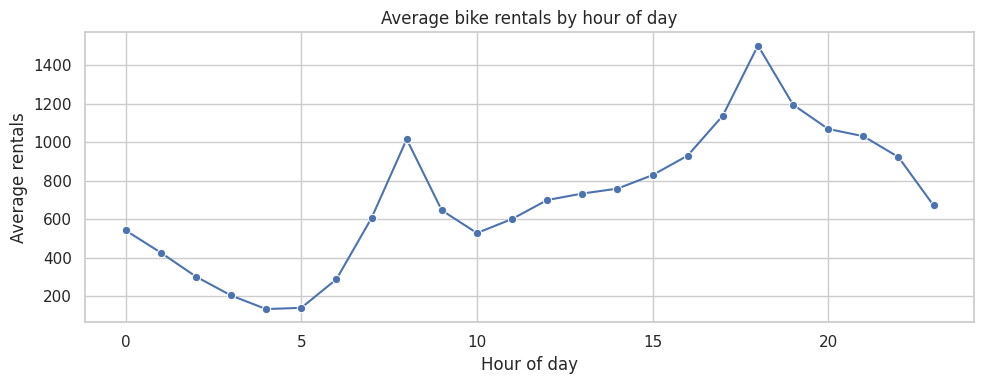

In [20]:
print("Date range:", df["datetime"].min(), "to", df["datetime"].max())
print("Average rentals per hour:", round(df["rentals"].mean(), 1))
print("Maximum rentals in one hour:", int(df["rentals"].max()))

hourly_pattern = df.groupby("hour", as_index=False)["rentals"].mean()
plt.figure(figsize=(10, 4))
sns.lineplot(data=hourly_pattern, x="hour", y="rentals", marker="o")
plt.title("Average bike rentals by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show()


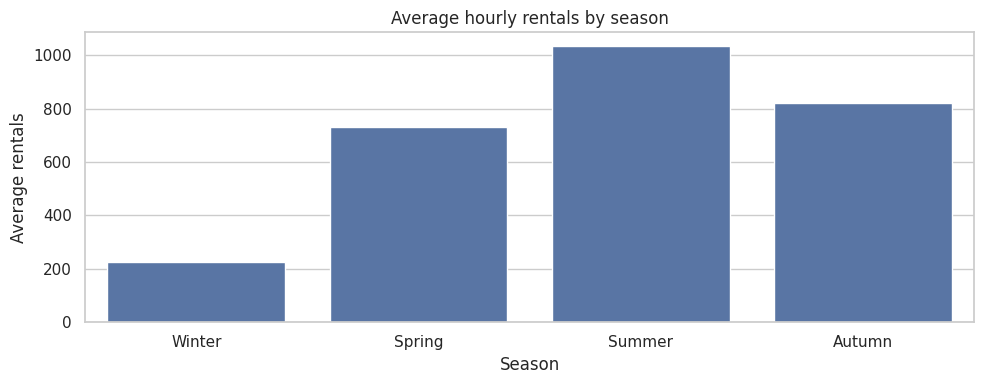

In [21]:
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x="season", y="rentals", errorbar=None)
plt.title("Average hourly rentals by season")
plt.xlabel("Season")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show()


In [22]:
# Repeating time features make 23:00 and 00:00 close in the model.
df["weekday"] = df["datetime"].dt.dayofweek
df["month"] = df["datetime"].dt.month
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["weekday_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
df["weekday_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)
df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

# Past rental counts; the current hour's answer is never an input.
df["demand_lag_1h"] = df["rentals"].shift(1)
df["demand_lag_24h"] = df["rentals"].shift(24)
df["demand_lag_168h"] = df["rentals"].shift(168)

# Use previous-hour weather, not target-hour observed weather.
weather_sources = [
    "temperature_c", "humidity_pct", "wind_speed_m_s", "visibility_10m",
    "dew_point_c", "solar_radiation_mj_m2", "rainfall_mm", "snowfall_cm"
]
weather_sources = [name for name in weather_sources if name in df.columns]
previous_weather_features = []
for name in weather_sources:
    numeric_weather = pd.to_numeric(df[name], errors="coerce")
    new_name = f"previous_{name}"
    df[new_name] = numeric_weather.shift(1)
    previous_weather_features.append(new_name)

categorical_features = ["season", "holiday", "functioning_day"]
numeric_features = [
    "hour_sin", "hour_cos", "weekday_sin", "weekday_cos",
    "month_sin", "month_cos", "demand_lag_1h",
    "demand_lag_24h", "demand_lag_168h"
] + previous_weather_features
feature_columns = numeric_features + categorical_features

model_df = df.dropna(
    subset=["demand_lag_1h", "demand_lag_24h", "demand_lag_168h"]
).copy()

print("Rows available for modeling:", len(model_df))
print("Input feature count:", len(feature_columns))
display(model_df[["datetime", "rentals"] + feature_columns].head())


Rows available for modeling: 8592
Input feature count: 20


,datetime,rentals,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,demand_lag_1h,demand_lag_24h,...,previous_humidity_pct,previous_wind_speed_m_s,previous_visibility_10m,previous_dew_point_c,previous_solar_radiation_mj_m2,previous_rainfall_mm,previous_snowfall_cm,season,holiday,functioning_day
168,2017-12-08 00:00:00,233,0.000000,1.000000,-0.433884,-0.900969,-0.5,0.866025,259.0,198.0,...,50.0,2.1,1887.0,-12.1,0.0,0.0,0.0,Winter,No Holiday,Yes
169,2017-12-08 01:00:00,230,0.258819,0.965926,-0.433884,-0.900969,-0.5,0.866025,233.0,218.0,...,49.0,2.6,1893.0,-12.6,0.0,0.0,0.0,Winter,No Holiday,Yes
170,2017-12-08 02:00:00,131,0.500000,0.866025,-0.433884,-0.900969,-0.5,0.866025,230.0,149.0,...,50.0,2.5,1902.0,-12.6,0.0,0.0,0.0,Winter,No Holiday,Yes
171,2017-12-08 03:00:00,99,0.707107,0.707107,-0.433884,-0.900969,-0.5,0.866025,131.0,102.0,...,53.0,1.0,1918.0,-12.4,0.0,0.0,0.0,Winter,No Holiday,Yes
172,2017-12-08 04:00:00,71,0.866025,0.500000,-0.433884,-0.900969,-0.5,0.866025,99.0,62.0,...,52.0,1.6,1978.0,-13.1,0.0,0.0,0.0,Winter,No Holiday,Yes


In [23]:
first_cut = int(len(model_df) * 0.70)
second_cut = int(len(model_df) * 0.85)

train = model_df.iloc[:first_cut].copy()
validation = model_df.iloc[first_cut:second_cut].copy()
test = model_df.iloc[second_cut:].copy()

print("Training period:", train["datetime"].min(), "to", train["datetime"].max())
print("Validation period:", validation["datetime"].min(), "to", validation["datetime"].max())
print("Test period:", test["datetime"].min(), "to", test["datetime"].max())
print("Rows:", len(train), "train |", len(validation), "validation |", len(test), "test")


Training period: 2017-12-08 00:00:00 to 2018-08-15 13:00:00
Validation period: 2018-08-15 14:00:00 to 2018-10-08 06:00:00
Test period: 2018-10-08 07:00:00 to 2018-11-30 23:00:00
Rows: 6014 train | 1289 validation | 1289 test


In [24]:
def make_preprocessor():
    numeric_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="median"))
    ])
    categorical_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numbers", numeric_steps, numeric_features),
        ("categories", categorical_steps, categorical_features)
    ])

candidate_model = Pipeline([
    ("prepare", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

X_train = train[feature_columns]
y_train = train["rentals"]
X_validation = validation[feature_columns]
y_validation = validation["rentals"]

candidate_model.fit(X_train, y_train)
validation_prediction = np.maximum(candidate_model.predict(X_validation), 0)
validation_baseline = validation["demand_lag_168h"].to_numpy()

def regression_scores(actual, predicted):
    return {
        "MAE (bikes/hour)": mean_absolute_error(actual, predicted),
        "RMSE (bikes/hour)": mean_squared_error(actual, predicted) ** 0.5
    }

validation_results = pd.DataFrame([
    {
        "Model": "Same hour last week",
        **regression_scores(y_validation, validation_baseline)
    },
    {
        "Model": "Random forest",
        **regression_scores(y_validation, validation_prediction)
    }
]).set_index("Model")

display(validation_results.round(1))


,MAE (bikes/hour),RMSE (bikes/hour)
Model,,
Same hour last week,507.2,785.0
Random forest,106.0,183.1


,Feature,MAE increase when shuffled
6,demand_lag_1h,597.71
0,hour_sin,68.95
8,demand_lag_168h,42.41
14,previous_solar_radiation_mj_m2,28.37
7,demand_lag_24h,25.67
1,hour_cos,20.41
2,weekday_sin,3.88
9,previous_temperature_c,1.73
10,previous_humidity_pct,0.75
11,previous_wind_speed_m_s,0.24


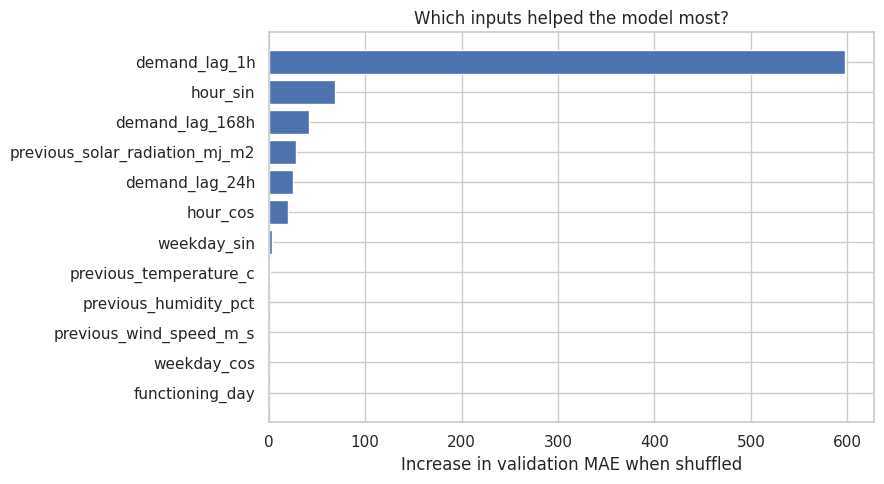

In [25]:
importance = permutation_importance(
    candidate_model,
    X_validation,
    y_validation,
    scoring="neg_mean_absolute_error",
    n_repeats=4,
    random_state=42,
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "MAE increase when shuffled": importance.importances_mean
}).sort_values("MAE increase when shuffled", ascending=False)

display(importance_table.head(12).round(2))

top_importance = importance_table.head(12).sort_values(
    "MAE increase when shuffled"
)
plt.figure(figsize=(9, 5))
plt.barh(
    top_importance["Feature"],
    top_importance["MAE increase when shuffled"]
)
plt.xlabel("Increase in validation MAE when shuffled")
plt.title("Which inputs helped the model most?")
plt.tight_layout()
plt.show()


In [26]:
train_and_validation = pd.concat([train, validation], axis=0)
final_model = Pipeline([
    ("prepare", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

final_model.fit(
    train_and_validation[feature_columns],
    train_and_validation["rentals"]
)

X_test = test[feature_columns]
y_test = test["rentals"]
test_prediction = np.maximum(final_model.predict(X_test), 0)
test_baseline = test["demand_lag_168h"].to_numpy()

test_results = pd.DataFrame([
    {
        "Model": "Same hour last week",
        **regression_scores(y_test, test_baseline)
    },
    {
        "Model": "Random forest",
        **regression_scores(y_test, test_prediction)
    }
]).set_index("Model")

display(test_results.round(1))

baseline_mae = test_results.loc["Same hour last week", "MAE (bikes/hour)"]
model_mae = test_results.loc["Random forest", "MAE (bikes/hour)"]
mae_improvement_pct = 100 * (baseline_mae - model_mae) / baseline_mae
print(f"MAE change versus baseline: {mae_improvement_pct:.1f}% improvement")


,MAE (bikes/hour),RMSE (bikes/hour)
Model,,
Same hour last week,340.0,548.8
Random forest,69.4,109.0


MAE change versus baseline: 79.6% improvement


In [27]:
test_predictions = pd.DataFrame({
    "datetime": test["datetime"].to_numpy(),
    "actual_demand": y_test.to_numpy(),
    "model_prediction": test_prediction,
    "weekly_baseline": test_baseline
})

reports_dir = Path("reports")
reports_dir.mkdir(exist_ok=True)
predictions_path = reports_dir / "test_predictions.csv"
test_predictions.to_csv(predictions_path, index=False)
print("Saved dashboard input to:", predictions_path)


Saved dashboard input to: reports/test_predictions.csv


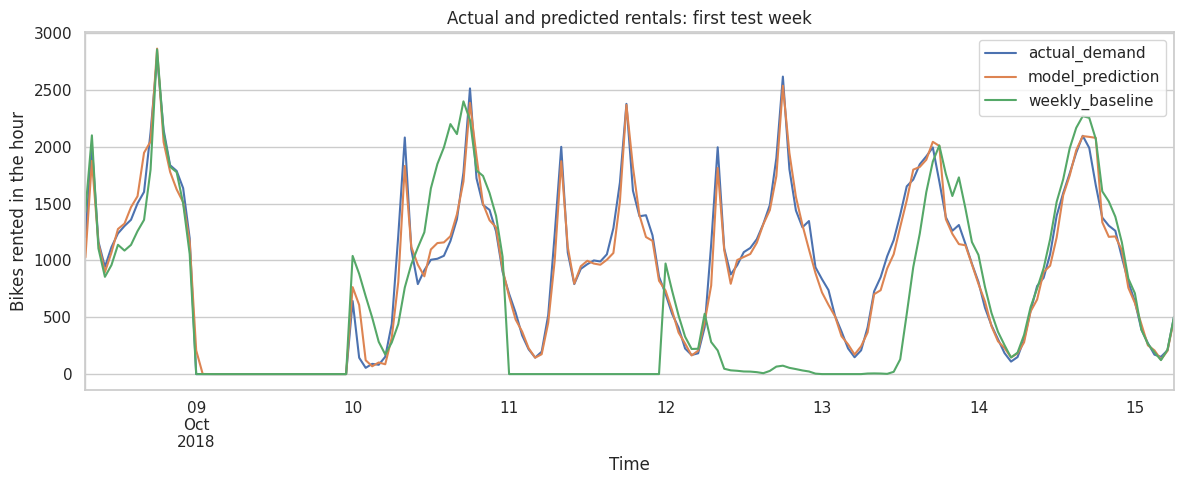

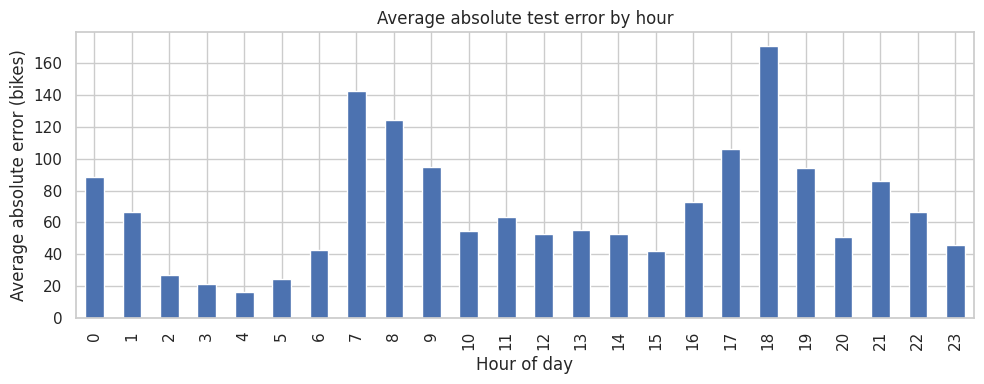

In [28]:
first_test_week = test_predictions.head(168).set_index("datetime")
first_test_week[
    ["actual_demand", "model_prediction", "weekly_baseline"]
].plot(figsize=(12, 5))
plt.title("Actual and predicted rentals: first test week")
plt.ylabel("Bikes rented in the hour")
plt.xlabel("Time")
plt.tight_layout()
plt.show()

test_predictions["absolute_error"] = (
    test_predictions["actual_demand"] - test_predictions["model_prediction"]
).abs()
test_predictions["hour"] = test_predictions["datetime"].dt.hour
hourly_error = test_predictions.groupby("hour")["absolute_error"].mean()

plt.figure(figsize=(10, 4))
hourly_error.plot(kind="bar")
plt.title("Average absolute test error by hour")
plt.xlabel("Hour of day")
plt.ylabel("Average absolute error (bikes)")
plt.tight_layout()
plt.show()
